# HDB Rentals: model training on the progress report's setup

The progress report fixed the features and the time treatment. This notebook does its three next steps
(slide 12):

1. **Single validation set.** One time split, used for every model below.
2. **Other models and tuning.** Linear regression, random forest, HistGradientBoosting, LightGBM, XGBoost and
   CatBoost, then a random search on the three boosters and a blend of them.
3. **Kaggle dry run.** Refit on all of train and write a submission file.

**What the report decided, and this notebook keeps:**

| decision | slide |
|---|---|
| Clean as slide 5: lowercase text, "4 room" = "4-room", drop `FURNISHED` / `FEE`, month counter `MONTH_INDEX` | 5 |
| Join HDB block table on town + block + street; planned MRTs and hawker centres under construction excluded | 6, 9 |
| Time enters only through `MONTH_INDEX`. No COE or other macro series, no month-of-year seasonality | 8 |
| Features: BASE (`FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX`, `TOWN`, `FLAT_TYPE`, `FLAT_MODEL`) + the distance set behind LightGBM 489.6 | 11 |
| Evaluation holdout: fit 2021-01 to 2023-12, score 2024-01 to 2025-03 | 11 |

The market-level work in `07_pipeline.ipynb` / `08_level_robustness.ipynb` came after the report and is not
used here.

1. Setup and cleaning
2. Location features
3. The validation set
4. Model comparison with default settings
5. Tuning the boosters
6. Blending
7. Error by months ahead
8. Kaggle dry run
9. Summary

In [1]:
import json
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
SEED = 0
T0 = time.time()

## 1. Setup and cleaning (slide 5)

Same cleaning as `07` §1. Train is sorted by month; test keeps the file's order, since the submission is matched
by row position.

In [2]:
def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = [c for c in out.columns if pd.api.types.is_string_dtype(out[c])]
    out[text] = out[text].apply(lambda s: s.str.strip().str.lower())
    return out


def clean_rent(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df).drop(columns=["FURNISHED", "FEE"])
    # "4 room" and "4-room" are the same level.
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    date = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["RENT_APPROVAL_DATE"] = date
    out["MONTH_INDEX"] = (date.dt.year - 2021) * 12 + date.dt.month - 1
    return out


raw_train, raw_test = pd.read_csv(DATA / "train.csv"), pd.read_csv(DATA / "test.csv")
train = clean_rent(raw_train).sort_values("MONTH_INDEX", kind="stable").reset_index(drop=True)
test = clean_rent(raw_test)
for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} {len(df):>7,} rows  {df['RENT_APPROVAL_DATE'].min():%Y-%m} to {df['RENT_APPROVAL_DATE'].max():%Y-%m}")

train 150,000 rows  2021-01 to 2025-03
test   50,000 rows  2025-03 to 2026-07


## 2. Location features (slides 6, 11)

Built as in `06_distance_features` §2 and `07` §2: haversine distances from every HDB block to open MRT stations,
primary and secondary schools, malls and open hawker centres, counted within 1 and 2 km and to the nearest one,
plus distance to the CBD (Raffles Place MRT).

`DIST` is the 13-column set behind slide 11's LightGBM 489.6 ("REFERENCE + everything new"): the 2 km school
and MRT counts, `MAX_FLOOR`, the 1 km mall and hawker counts, and the nearest distances.

In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv", dtype={"POSTAL_CODE": str})
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
malls = lower_strip(pd.read_csv(DATA / "auxiliary" / "sg-shopping-malls.csv"))

with open(DATA / "auxiliary" / "HawkerCentresGEOJSON.geojson") as f:
    features = json.load(f)["features"]
hawker = lower_strip(pd.DataFrame({
    "NAME": [feat["properties"]["NAME"] for feat in features],
    "STATUS": [feat["properties"]["STATUS"] for feat in features],
    "LONGITUDE": [feat["geometry"]["coordinates"][0] for feat in features],
    "LATITUDE": [feat["geometry"]["coordinates"][1] for feat in features],
}))

mrt_open = mrt[mrt["STATUS"].eq("open")].drop_duplicates("NAME")
POI_GROUPS = {
    "primary": schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)],
    "secondary": schools[schools["MAINLEVEL_CODE"].str.contains("secondary", na=False)],
    "mrt": mrt_open,
    "mrt_interchange": mrt_open[mrt_open["IS_INTERCHANGE"]],
    "malls": malls,
    "hawker": hawker[hawker["STATUS"].ne("under construction")],
}
RADII_KM = {"1km": 1.0, "2km": 2.0}

lat, lon = hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy()
for prefix, poi in POI_GROUPS.items():
    d = haversine_km(lat[:, None], lon[:, None], poi["LATITUDE"].to_numpy()[None, :], poi["LONGITUDE"].to_numpy()[None, :])
    hdb[f"{prefix}_nearest_km"] = d.min(axis=1)
    for label, r in RADII_KM.items():
        hdb[f"{prefix}_within_{label}"] = (d <= r).sum(axis=1)
cbd = mrt.loc[mrt["NAME"].eq("raffles place mrt station"), ["LATITUDE", "LONGITUDE"]].iloc[0]
hdb["dist_to_cbd_km"] = haversine_km(lat, lon, cbd["LATITUDE"], cbd["LONGITUDE"])

DIST = [
    "MAX_FLOOR", "primary_within_2km", "mrt_within_2km",
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km",
    "mrt_interchange_within_1km", "mrt_interchange_nearest_km",
    "malls_within_1km", "malls_nearest_km", "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
]
train = train.merge(hdb[KEY + DIST], on=KEY, how="left", validate="m:1")
test = test.merge(hdb[KEY + DIST], on=KEY, how="left", validate="m:1")
assert len(train) == len(raw_train) and len(test) == len(raw_test)
print("rows with no block match: train", int(train["dist_to_cbd_km"].isna().sum()), " test", int(test["dist_to_cbd_km"].isna().sum()))
print("MAX_FLOOR missing (SERS blocks): train", int(train["MAX_FLOOR"].isna().sum()), " test", int(test["MAX_FLOOR"].isna().sum()))

rows with no block match: train 0  test 0
MAX_FLOOR missing (SERS blocks): train 159  test 0


## 3. The validation set (next step 1)

One time split, used for every number below:

- **Holdout:** fit 2021-01 to 2023-12, score 2024-01 to 2025-03 (15 months), the split behind slide 11. The test
  window is 2025-03 to 2026-07, 1 to 16 months past the last label, so the holdout is scored at a similar
  distance ahead.
- **Tuning split, inside the holdout's fit months:** fit 2021-01 to 2023-03, score 2023-04 to 2023-12. Hyperparameter
  search, early stopping and blend weights are chosen here only, so the holdout is scored once per final
  configuration and is not used to pick anything.

Metrics: RMSE (the competition metric), MAE, and bias = mean(prediction − actual), so negative means
under-prediction.

In [4]:
HOLDOUT_START, TUNE_START = "2024-01", "2023-04"
date = train["RENT_APPROVAL_DATE"]
fit = train[date < HOLDOUT_START].reset_index(drop=True)
holdout = train[date >= HOLDOUT_START].reset_index(drop=True)
tune_fit = fit[fit["RENT_APPROVAL_DATE"] < TUNE_START].reset_index(drop=True)
tune_val = fit[fit["RENT_APPROVAL_DATE"] >= TUNE_START].reset_index(drop=True)

span = lambda df: f"{df['RENT_APPROVAL_DATE'].min():%Y-%m} to {df['RENT_APPROVAL_DATE'].max():%Y-%m}"
pd.DataFrame([
    {"split": "holdout", "fit": span(fit), "fit rows": len(fit), "scored": span(holdout), "scored rows": len(holdout)},
    {"split": "tuning", "fit": span(tune_fit), "fit rows": len(tune_fit), "scored": span(tune_val), "scored rows": len(tune_val)},
]).set_index("split")

,fit,fit rows,scored,scored rows
split,,,,
holdout,2021-01 to 2023-12,105837,2024-01 to 2025-03,44163
tuning,2021-01 to 2023-03,78960,2023-04 to 2023-12,26877


## 4. Model comparison with default settings (next step 3)

Every model gets the same columns. Categorical level sets are fixed once from all of train, so the folds and the
test file share one code per level. Encoding differs by model:

- **Linear regression:** median-impute and scale numerics, one-hot categoricals (as `03`).
- **Random forest, HistGradientBoosting:** ordinal-coded categoricals (native categorical splits for HGB).
- **LightGBM, XGBoost, CatBoost:** native categoricals, `MAX_FLOOR` left missing for the SERS blocks.

Settings are each library's usual starting point; LightGBM uses the report's (`n_estimators=400`,
`learning_rate=0.05`, `num_leaves=31`), so its holdout RMSE should reproduce slide 11's 489.6.

In [5]:
NUM = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"] + DIST
CAT = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]
FEATURES = NUM + CAT
CATEGORIES = {c: pd.CategoricalDtype(sorted(train[c].unique())) for c in CAT}
assert all(test[c].isin(CATEGORIES[c].categories).all() for c in CAT), "test has a level train never had"


def matrix(df):
    X = df[FEATURES].copy()
    for c in CAT:
        X[c] = X[c].astype(CATEGORIES[c])
    return X


def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y, float) - np.asarray(p, float)) ** 2)))


def score(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"rmse": rmse(y, p), "mae": float(np.mean(np.abs(p - y))), "bias": float(np.mean(p - y))}


def ordinal_pre():
    cats = [list(CATEGORIES[c].categories) for c in CAT]
    return ColumnTransformer([("cat", OrdinalEncoder(categories=cats), CAT), ("num", "passthrough", NUM)])


def make_model(name, params=None):
    p = params or {}
    if name == "Linear regression":
        pre = ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ])
        return Pipeline([("pre", pre), ("m", LinearRegression())])
    if name == "Random forest":
        rf = RandomForestRegressor(**{"n_estimators": 300, "min_samples_leaf": 5, "max_features": 0.5, **p},
                                   n_jobs=-1, random_state=SEED)
        return Pipeline([("pre", ordinal_pre()), ("m", rf)])
    if name == "HistGradientBoosting":
        hgb = HistGradientBoostingRegressor(**{"max_iter": 400, "learning_rate": 0.05, **p},
                                            categorical_features=list(range(len(CAT))), random_state=SEED)
        return Pipeline([("pre", ordinal_pre()), ("m", hgb)])
    if name == "LightGBM":
        return lgb.LGBMRegressor(**{"n_estimators": 400, "learning_rate": 0.05, "num_leaves": 31, **p},
                                 verbose=-1, n_jobs=-1, random_state=SEED)
    if name == "XGBoost":
        return xgb.XGBRegressor(**{"n_estimators": 400, "learning_rate": 0.05, "max_depth": 8, **p},
                                tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
                                n_jobs=-1, random_state=SEED)
    if name == "CatBoost":
        return CatBoostRegressor(**{"iterations": 1000, "learning_rate": 0.1, "depth": 8, **p},
                                 cat_features=CAT, loss_function="RMSE", thread_count=-1,
                                 random_seed=SEED, verbose=0, allow_writing_files=False)
    raise ValueError(name)


def to_input(name, df):
    # CatBoost wants plain strings for categoricals; the others take the fixed-level frame.
    X = matrix(df)
    if name == "CatBoost":
        X[CAT] = X[CAT].astype(str)
    return X


def fit_predict(name, fit_df, apply_df, params=None):
    est = make_model(name, params)
    est.fit(to_input(name, fit_df), fit_df[TARGET].to_numpy())
    return est.predict(to_input(name, apply_df))

In [6]:
MODELS = ["Linear regression", "Random forest", "HistGradientBoosting", "LightGBM", "XGBoost", "CatBoost"]
y_hold = holdout[TARGET].to_numpy()

default_rows, hold_preds = [], {}
for name in MODELS:
    t = time.time()
    hold_preds[f"{name} (default)"] = p = fit_predict(name, fit, holdout)
    default_rows.append({"model": name, **score(y_hold, p), "fit + predict (s)": time.time() - t})
default_table = pd.DataFrame(default_rows).set_index("model").sort_values("rmse")
default_table

,rmse,mae,bias,fit + predict (s)
model,,,,
LightGBM,489.58,366.51,-38.11,0.73
HistGradientBoosting,490.68,367.35,-36.08,0.65
XGBoost,496.68,370.66,-33.83,1.19
CatBoost,498.44,372.90,-34.22,39.60
Random forest,503.31,376.46,-39.79,4.28
Linear regression,652.61,495.09,391.28,0.41


- **LightGBM reproduces slide 11 exactly: 489.58.** Linear regression gives 652.6 (slide 11: 652.4; the spec
  here carries all 13 `DIST` columns).
- **HistGradientBoosting ties LightGBM** (490.7, +1.1). At their starting settings XGBoost (+7.1), CatBoost
  (+8.9) and random forest (+13.7) are behind.
- **Every tree under-predicts by 34 to 40**; linear regression over-predicts by 391. A linear `MONTH_INDEX`
  keeps extending the 2021-23 climb into the 2024 plateau; a tree holds the last level (slide 8).
- Linear regression and random forest are dropped from here on; HistGradientBoosting is not tuned either, since
  it is LightGBM's algorithm and the search below covers LightGBM.

## 5. Tuning the boosters (next step 3)

LightGBM, XGBoost and CatBoost each get their starting settings plus 20 random draws, scored on the tuning split
only. Every draw uses early stopping on the tuning split's scored months (patience 100 rounds, learning rate
fixed at 0.05), so the search covers tree shape and regularisation and the number of rounds is found, not
guessed. The best draw per library is then refit on the holdout's fit months with that many rounds and scored on
the holdout once.

Random forest, HistGradientBoosting and linear regression are not tuned: section 4 already puts them well behind.

In [7]:
N_DRAWS = 20
LR = 0.05
MAX_ROUNDS = 5000
rng = np.random.default_rng(SEED)
y_tune = tune_val[TARGET].to_numpy()

SPACE = {
    "LightGBM": (
        {"num_leaves": 31},
        lambda: {"num_leaves": int(rng.choice([31, 63, 127, 255, 511])),
                 "min_child_samples": int(rng.choice([5, 10, 20, 50, 100])),
                 "subsample": float(rng.choice([0.7, 0.85, 1.0])), "subsample_freq": 1,
                 "colsample_bytree": float(rng.choice([0.5, 0.7, 0.85, 1.0])),
                 "reg_lambda": float(rng.choice([0.0, 1.0, 5.0, 20.0])),
                 "cat_smooth": float(rng.choice([1.0, 10.0, 30.0]))},
    ),
    "XGBoost": (
        {"max_depth": 8},
        lambda: {"max_depth": int(rng.choice([6, 8, 10, 12])),
                 "min_child_weight": float(rng.choice([1, 5, 10, 30])),
                 "subsample": float(rng.choice([0.7, 0.85, 1.0])),
                 "colsample_bytree": float(rng.choice([0.5, 0.7, 0.85, 1.0])),
                 "reg_lambda": float(rng.choice([1.0, 5.0, 20.0])),
                 "max_cat_threshold": int(rng.choice([16, 32, 64]))},
    ),
    "CatBoost": (
        {"depth": 8},
        lambda: {"depth": int(rng.choice([6, 8, 10])),
                 "l2_leaf_reg": float(rng.choice([1.0, 3.0, 10.0, 30.0])),
                 "random_strength": float(rng.choice([0.5, 1.0, 2.0])),
                 "rsm": float(rng.choice([0.5, 0.75, 1.0])),
                 "one_hot_max_size": int(rng.choice([2, 10, 50]))},
    ),
}


def fit_early_stopped(name, params, fit_df, eval_df):
    # Train with early stopping on eval_df; return (predictions on eval_df, rounds used).
    Xf, Xe = to_input(name, fit_df), to_input(name, eval_df)
    yf, ye = fit_df[TARGET].to_numpy(), eval_df[TARGET].to_numpy()
    if name == "LightGBM":
        est = make_model(name, {**params, "n_estimators": MAX_ROUNDS, "learning_rate": LR})
        est.fit(Xf, yf, eval_X=Xe, eval_y=ye, callbacks=[lgb.early_stopping(100, verbose=False)])
        return est.predict(Xe), est.best_iteration_
    if name == "XGBoost":
        est = make_model(name, {**params, "n_estimators": MAX_ROUNDS, "learning_rate": LR, "early_stopping_rounds": 100})
        est.fit(Xf, yf, eval_set=[(Xe, ye)], verbose=False)
        return est.predict(Xe, iteration_range=(0, est.best_iteration + 1)), est.best_iteration + 1
    if name == "CatBoost":
        est = make_model(name, {**params, "iterations": MAX_ROUNDS, "learning_rate": LR,
                                "od_type": "Iter", "od_wait": 100, "use_best_model": True})
        est.fit(Xf, yf, eval_set=(Xe, ye))
        return est.predict(Xe), est.get_best_iteration() + 1
    raise ValueError(name)


search_rows, tune_preds = [], {}
for name, (start, draw) in SPACE.items():
    for i, params in enumerate([start] + [draw() for _ in range(N_DRAWS)]):
        t = time.time()
        p, rounds = fit_early_stopped(name, params, tune_fit, tune_val)
        tune_preds[(name, i)] = p
        search_rows.append({"model": name, "draw": i, "tune rmse": rmse(y_tune, p), "rounds": rounds,
                            "seconds": time.time() - t, "params": params})
search = pd.DataFrame(search_rows)
print(f"search time: {search['seconds'].sum() / 60:.1f} min")
search.sort_values("tune rmse").groupby("model").head(3).sort_values(["model", "tune rmse"])[
    ["model", "draw", "tune rmse", "rounds", "params"]]

search time: 6.3 min


,model,draw,tune rmse,rounds,params
53,CatBoost,11,602.35,997,"{'depth': 6, 'l2_leaf_reg': 30.0, 'random_stre..."
61,CatBoost,19,602.68,647,"{'depth': 6, 'l2_leaf_reg': 3.0, 'random_stren..."
51,CatBoost,9,602.89,618,"{'depth': 6, 'l2_leaf_reg': 10.0, 'random_stre..."
5,LightGBM,5,603.15,266,"{'num_leaves': 63, 'min_child_samples': 100, '..."
16,LightGBM,16,603.21,295,"{'num_leaves': 63, 'min_child_samples': 100, '..."
2,LightGBM,2,603.48,207,"{'num_leaves': 31, 'min_child_samples': 5, 'su..."
40,XGBoost,19,603.09,257,"{'max_depth': 6, 'min_child_weight': 30.0, 'su..."
33,XGBoost,12,603.44,279,"{'max_depth': 6, 'min_child_weight': 30.0, 'su..."
30,XGBoost,9,603.70,254,"{'max_depth': 6, 'min_child_weight': 5.0, 'sub..."


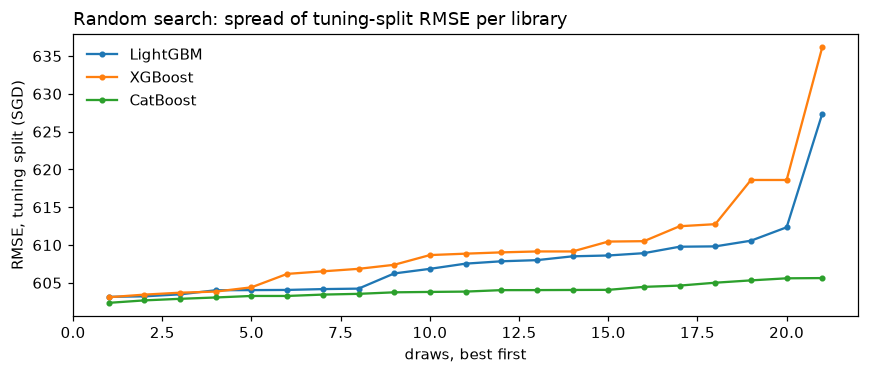

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in SPACE:
    s = search[search["model"] == name]["tune rmse"].sort_values().to_numpy()
    ax.plot(np.arange(1, len(s) + 1), s, marker="o", ms=3, label=name)
ax.set_xlabel("draws, best first")
ax.set_ylabel("RMSE, tuning split (SGD)")
ax.set_title("Random search: spread of tuning-split RMSE per library", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Holdout score of each library's best draw.** Refit on 2021-01 to 2023-12 with the chosen settings and number
of rounds, scored once on 2024-01 to 2025-03. The holdout's fit months are 9 more than the tuning split's, so
the round count is scaled up by the same ratio of rows.

In [9]:
best = search.loc[search.groupby("model")["tune rmse"].idxmin()].set_index("model")
round_scale = len(fit) / len(tune_fit)
ROUNDS_KEY = {"LightGBM": "n_estimators", "XGBoost": "n_estimators", "CatBoost": "iterations"}


def final_params(name, rounds):
    return {**best.loc[name, "params"], ROUNDS_KEY[name]: int(round(rounds * round_scale)), "learning_rate": LR}


tuned_rows = []
for name in SPACE:
    params = final_params(name, best.loc[name, "rounds"])
    t = time.time()
    hold_preds[f"{name} (tuned)"] = p = fit_predict(name, fit, holdout, params)
    tuned_rows.append({"model": name, "default rmse": default_table.loc[name, "rmse"], "tuned rmse": score(y_hold, p)["rmse"],
                       "tuned bias": score(y_hold, p)["bias"], "tune-split rmse": best.loc[name, "tune rmse"],
                       "rounds": params[ROUNDS_KEY[name]], "seconds": time.time() - t})
tuned_table = pd.DataFrame(tuned_rows).set_index("model")
tuned_table["gain"] = tuned_table["default rmse"] - tuned_table["tuned rmse"]
display(tuned_table.sort_values("tuned rmse"))
for name in SPACE:
    print(f"{name:<9}", final_params(name, best.loc[name, "rounds"]))

,default rmse,tuned rmse,tuned bias,tune-split rmse,rounds,seconds,gain
model,,,,,,,
LightGBM,489.58,487.49,-35.03,603.15,357,1.04,2.08
XGBoost,496.68,489.64,-36.61,603.09,344,0.80,7.04
CatBoost,498.44,490.37,-38.90,602.35,1336,35.11,8.08


LightGBM  {'num_leaves': 63, 'min_child_samples': 100, 'subsample': 0.85, 'subsample_freq': 1, 'colsample_bytree': 0.5, 'reg_lambda': 20.0, 'cat_smooth': 30.0, 'n_estimators': 357, 'learning_rate': 0.05}
XGBoost   {'max_depth': 6, 'min_child_weight': 30.0, 'subsample': 0.7, 'colsample_bytree': 0.85, 'reg_lambda': 20.0, 'max_cat_threshold': 64, 'n_estimators': 344, 'learning_rate': 0.05}
CatBoost  {'depth': 6, 'l2_leaf_reg': 30.0, 'random_strength': 2.0, 'rsm': 0.5, 'one_hot_max_size': 10, 'iterations': 1336, 'learning_rate': 0.05}


- **Tuning helps, but only by a few dollars:** LightGBM 489.6 → 487.5 (−2.1), XGBoost 496.7 → 489.6 (−7.0),
  CatBoost 498.4 → 490.4 (−8.1). The three libraries end up within 3 of each other.
- **All three searches pick the same kind of model:** shallower, heavily regularised trees. LightGBM
  63 leaves, `min_child_samples=100`, `reg_lambda=20`, half the columns per tree; XGBoost depth 6,
  `min_child_weight=30`, `reg_lambda=20`; CatBoost depth 6, `l2_leaf_reg=30`. Months ahead are a different market
  from the fit months, so smoother fits travel better.
- **The tuning split cannot rank the libraries.** CatBoost is best there (602.4 vs 603.1 and 603.2) and worst on
  the holdout. Differences under 1 on one split are noise. The tuning split's RMSE is higher in absolute terms
  because 2023 rents were still rising, so the held level is further off.

## 6. Blending

The three tuned boosters are averaged with weights chosen on the tuning split (a grid over weights that sum to 1,
step 0.05), then applied unchanged to the holdout predictions. An equal-weight average is shown next to it.

In [10]:
BOOSTERS = list(SPACE)
tune_best = np.column_stack([tune_preds[(m, int(best.loc[m, "draw"]))] for m in BOOSTERS])
hold_best = np.column_stack([hold_preds[f"{m} (tuned)"] for m in BOOSTERS])

grid = np.round(np.arange(0, 1.0001, 0.05), 2)
weights = [(a, b, round(1 - a - b, 2)) for a in grid for b in grid if a + b <= 1 + 1e-9]
blend_search = pd.DataFrame([{"w": w, "tune rmse": rmse(y_tune, tune_best @ np.array(w))} for w in weights])
W = np.array(blend_search.loc[blend_search["tune rmse"].idxmin(), "w"])
print("blend weights chosen on the tuning split:", dict(zip(BOOSTERS, W)))

hold_preds["blend (tuned weights)"] = hold_best @ W
hold_preds["blend (equal weights)"] = hold_best.mean(axis=1)

ranked = ["LightGBM (default)"] + [f"{m} (tuned)" for m in BOOSTERS] + ["blend (equal weights)", "blend (tuned weights)"]
blend_table = pd.DataFrame({k: score(y_hold, hold_preds[k]) for k in ranked}).T
blend_table["vs report (489.6)"] = blend_table["rmse"] - default_table.loc["LightGBM", "rmse"]
blend_table

blend weights chosen on the tuning split: {'LightGBM': np.float64(0.35), 'XGBoost': np.float64(0.1), 'CatBoost': np.float64(0.55)}


,rmse,mae,bias,vs report (489.6)
LightGBM (default),489.58,366.51,-38.11,0.00
LightGBM (tuned),487.49,364.30,-35.03,-2.08
XGBoost (tuned),489.64,366.40,-36.61,0.06
CatBoost (tuned),490.37,367.55,-38.90,0.79
blend (equal weights),487.90,364.99,-36.85,-1.68
blend (tuned weights),488.01,365.20,-37.32,-1.57


In [11]:
print("correlation of holdout errors between the tuned boosters:")
pd.DataFrame(hold_best - y_hold[:, None], columns=BOOSTERS).corr()

correlation of holdout errors between the tuned boosters:


,LightGBM,XGBoost,CatBoost
LightGBM,1.00,0.99,0.99
XGBoost,0.99,1.00,0.99
CatBoost,0.99,0.99,1.00


- **Blending buys nothing.** The three boosters' holdout errors correlate at 0.99: they make the same mistakes.
  Equal weights give 487.9, tuning-split weights 488.0; tuned LightGBM alone is 487.5.
- **From the report's LightGBM to the best model here is 2.1 RMSE (0.4%).** The model is not where the error is.

## 7. Error by months ahead

The report's finding (slide 8) was that a tree on `MONTH_INDEX` holds the level of its last training month, so
it under-predicts more the further ahead it scores. The holdout is broken down by months past 2023-12 for the
report's LightGBM and for the final blend.

In [12]:
ahead = holdout["MONTH_INDEX"].to_numpy() - fit["MONTH_INDEX"].max()
BUCKETS = [(1, 3), (4, 6), (7, 9), (10, 12), (13, 15)]
horizon = {}
for k in ["LightGBM (default)", "blend (tuned weights)"]:
    rows = []
    for lo, hi in BUCKETS:
        sel = (ahead >= lo) & (ahead <= hi)
        rows.append({"months ahead": f"{lo}-{hi}", "n": int(sel.sum()), **score(y_hold[sel], hold_preds[k][sel])})
    horizon[k] = pd.DataFrame(rows).set_index("months ahead")[["n", "rmse", "bias"]]
pd.concat(horizon, axis=1)

LightGBM (default)               blend (tuned weights)              
                              n   rmse   bias                     n   rmse   bias
months ahead                                                                     
1-3                        9005 529.14   1.96                  9005 527.12   2.81
4-6                        9174 508.66 -11.82                  9174 506.59 -11.99
7-9                        8786 483.92 -55.04                  8786 483.05 -53.68
10-12                      8274 456.07 -64.16                  8274 454.08 -63.37
13-15                      8924 462.84 -64.75                  8924 462.01 -63.58

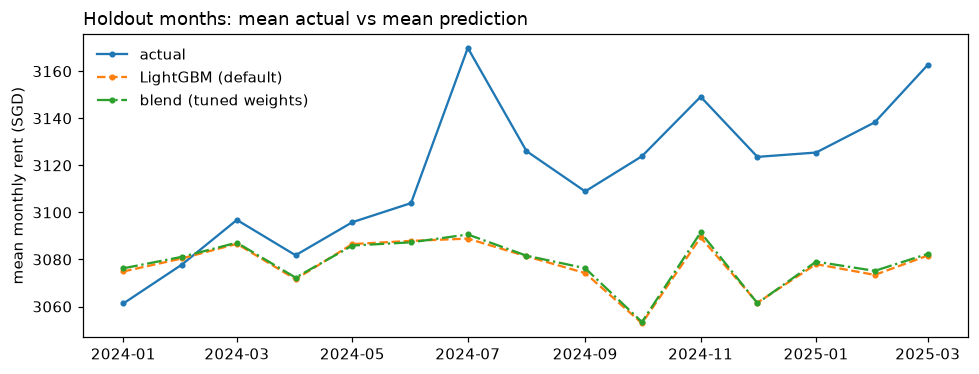

In [13]:
month = holdout["RENT_APPROVAL_DATE"]
by_month = pd.DataFrame({"actual": y_hold, "LightGBM (default)": hold_preds["LightGBM (default)"],
                         "blend (tuned weights)": hold_preds["blend (tuned weights)"]}).groupby(month.to_numpy()).mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
for col, style in [("actual", "-"), ("LightGBM (default)", "--"), ("blend (tuned weights)", "-.")]:
    ax.plot(by_month.index, by_month[col], style, marker="o", ms=3, label=col)
ax.set_ylabel("mean monthly rent (SGD)")
ax.set_title("Holdout months: mean actual vs mean prediction", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **Slide 8's horizon problem is unchanged.** Bias is about 0 at 1-3 months ahead and −64 at 13-15, for the
  report's LightGBM and for the blend alike (within 1.4 in every bucket). Tuning and blending tighten the fit
  around the held level; they do not move the level.
- The plot shows it: past 2023-12 the mean prediction stays flat while the actual mean keeps rising slowly.

## 8. Kaggle dry run (next step 2)

Each tuned booster is refit on all of train (2021-01 to 2025-03), with its round count scaled to the larger
training set as in section 5, and the three are blended with the weights from section 6. Two files, each one
`MONTHLY_RENT` column in the test file's row order (the same format as `07`'s `outputs/submission.csv`, which is
not overwritten):

- `outputs/submission_09_blend.csv`: the blend, the configuration chosen on the tuning split;
- `outputs/submission_09_lgbm.csv`: tuned LightGBM alone, best on the holdout (section 6).

Submitting both is a cheap check of whether the leaderboard agrees with the holdout on a 0.5-RMSE difference.

In [14]:
full_scale = len(train) / len(tune_fit)
test_cols = {}
for name in BOOSTERS:
    params = {**final_params(name, best.loc[name, "rounds"]),
              ROUNDS_KEY[name]: int(round(best.loc[name, "rounds"] * full_scale))}
    test_cols[name] = fit_predict(name, train, test, params)
test_matrix = pd.DataFrame(test_cols)
test_pred = test_matrix.to_numpy() @ W
assert len(test_pred) == len(raw_test) and np.isfinite(test_pred).all()

for path, pred in [(OUT / "submission_09_blend.csv", test_pred), (OUT / "submission_09_lgbm.csv", test_matrix["LightGBM"])]:
    pd.DataFrame({TARGET: pred}).to_csv(path, index=False)
    print(f"wrote {path}: {len(pred):,} rows")
print("correlation between the boosters' test predictions:")
display(test_matrix.corr())

test_month = test["RENT_APPROVAL_DATE"].dt.strftime("%Y-%m").to_numpy()
last3 = train[train["MONTH_INDEX"] >= train["MONTH_INDEX"].max() - 2]
print("train, last three months, median rent:", last3.groupby(last3["RENT_APPROVAL_DATE"].dt.strftime("%Y-%m"))[TARGET].median().to_dict())
pd.Series(test_pred, index=test_month).groupby(level=0).median().rename("median prediction").iloc[::3].to_frame()

wrote ..\outputs\submission_09_blend.csv: 50,000 rows
wrote ..\outputs\submission_09_lgbm.csv: 50,000 rows
correlation between the boosters' test predictions:


,LightGBM,XGBoost,CatBoost
LightGBM,1.00,1.00,0.99
XGBoost,1.00,1.00,0.99
CatBoost,0.99,0.99,1.00


train, last three months, median rent: {'2025-01': 3100.0, '2025-02': 3150.0, '2025-03': 3200.0}


,median prediction
2025-03,"3,139.97"
2025-06,"3,165.18"
2025-09,"3,130.80"
2025-12,"3,147.09"
2026-03,"3,134.50"
2026-06,"3,148.73"


- Both files: 50,000 rows, no missing values, every test town / flat type / flat model seen in train.
- **The test predictions are flat at the end-of-train level:** median 3,130 to 3,165 in every test month, against
  actual medians of 3,100, 3,150 and 3,200 in the last three training months. If rents keep rising through
  2026, expect the same under-prediction as in section 7 (about −60 at 7+ months ahead).
- Not yet submitted: uploading to Kaggle and recording the public score is left to the team.

## 9. Summary

**Next steps from slide 12, done here:**

- **1. Single validation set:** fit 2021-01 to 2023-12, score 2024-01 to 2025-03. Tuning, early stopping and blend
  weights use a separate split inside the fit months (fit to 2023-03, score 2023-04 to 2023-12).
- **3. Other models and tuning** (holdout RMSE, lower is better):

  | model | default | tuned |
  |---|---|---|
  | LightGBM (report: 489.6) | 489.6 | **487.5** |
  | XGBoost | 496.7 | 489.6 |
  | CatBoost | 498.4 | 490.4 |
  | HistGradientBoosting | 490.7 | not tuned |
  | Random forest | 503.3 | not tuned |
  | Linear regression (report: 652.4) | 652.6 | not tuned |
  | Blend of the three tuned boosters | | 488.0 |

- **2. Kaggle dry run:** `outputs/submission_09_blend.csv` (blend) and `outputs/submission_09_lgbm.csv` (tuned
  LightGBM). Not yet uploaded.

**What this says:**

- The report's LightGBM was already close to the best these models can do with these features. Tuning and other
  libraries add up to 2.1 RMSE; blending adds nothing, because the boosters' errors correlate at 0.99.
- Regularised, shallower trees win in every library, which suits forecasting a market that has moved since the
  fit months.
- The remaining error is the level, not the model: every model here holds the end-of-train level, and
  under-predicts by about 64 at 13-15 months ahead. `07`/`08` (after the report) test level forecasts; that is
  the direction with room left, not more model tuning.

In [15]:
print(f"runtime: {(time.time() - T0) / 60:.1f} min")

runtime: 8.7 min
